# Lecture 20 notebook: statistics of the flow

This notebook replays Lecture 20 on Bybit's and Binance's BTCUSDT perpetuals. Every figure and number of the lecture comes from a script in
`scripts/`, next to this notebook; each runs in a fresh process, so that memory is freed after every step.

| § | Content | Lecture |
|---|---|---|
| 0 | Settings | |
| 1 | A level forgets, a delta adds up: the key chart | §1 |
| 2 | The five measures on invented flows | §2 |
| 3 | On our 45 days: order-flow imbalance, impact, VPIN, Hawkes, lead and lag, the Lecture 19 puzzle, verdicts | §3 |
| 4 | 10 October: the hours before the post, and the early-warning table | §4 |
| 5 | The follow-ups: audits of H3 and H6, Kyle's lambda, the price before the post | §3, §4 |
| 6 | A test of your own: the branching ratio through the day | §5.2 |

**Three switches, all off by default.** Heavy steps run only when you switch them on in §0.

* **Off (default): the figures and tables only.** All 16 figures and the tables of the tests are redrawn from the small results shipped in
  `results/`, and match the lecture's exactly. No market data is needed; it takes about two minutes, most of it for saving the pictures.
* **`RUN_CHECK = True`: one day.** Every measure is rerun on `CHECK_DAY` and compared with the lecture's values for that day, and the audits of
  H3 and H6 (§5) are rerun, since they use that day. It needs the Parquet tables of Lecture 18 for `CHECK_DAY` (`BYBIT_ROOT`, default `data/bybit`
  at the top of the repository) and Binance's trades of that day (`BINANCE_ROOT`, default `data/binance`), and takes about ten minutes, most of it
  for replaying the book (§3).
* **`RUN_ALL = True`: everything.** Every measure is recomputed on every day in the data folder, the tests are rerun, and the figures are drawn
  from the new results. On the 45 days of the lecture (20 September – 3 November 2025) this takes six to seven hours. It first runs the steps of
  Lectures 18 and 19 whose results this lecture uses, with their own scripts, unchanged: the pulls (Lecture 18), the book state, the samples, the
  queue passes and Binance's prices (Lecture 19).
* **`RUN_FOLLOWUPS = True`** reruns the follow-ups on Kyle's lambda and on the price before the post (§5), which read all 45 days; it needs the
  results of `RUN_ALL` and takes about a quarter of an hour.

Results go to `BYBIT_ROOT/interim/l20` (or `L20_OUT`); figures are saved in `figures/` as `nb_*`, so the lecture's own figures are never
overwritten.

## 0. Settings

In [1]:
import io, json, os, subprocess, sys, time, urllib.request, zipfile
from pathlib import Path
import numpy as np, polars as pl, psutil
from IPython.display import Image, display

HERE = Path.cwd(); SCRIPTS, FIG = HERE / "scripts", HERE / "figures"
OTHER = {18: HERE.parent / "18-the-order-book" / "scripts", 19: HERE.parent / "19-statistics-of-the-book" / "scripts", 20: SCRIPTS}
sys.path[:0] = [str(SCRIPTS)]
import l20 as L
CHECK_DAY = "2025-10-01"                                                   # the day on which every measure is rerun (the day of the key chart)
RUN_CHECK = False                                                          # True: rerun every measure on CHECK_DAY (about 10 minutes)
RUN_ALL = False                                                            # True: recompute everything on every day (six to seven hours)
RUN_FOLLOWUPS = False                                                      # True: rerun the follow-ups on all days (needs RUN_ALL's results)
DOWNLOAD_BINANCE = False                                                   # True: download Binance's daily trades that are missing

pl.Config.set_tbl_rows(50); pl.Config.set_fmt_str_lengths(80); pl.Config.set_tbl_width_chars(200)
print("data folder:", L.ROOT, "| results:", L.OUT)
print("days with a book:", len(L.days()), (L.days()[0], L.days()[-1]) if L.days() else "")
print(f"free memory: {psutil.virtual_memory().available / 1e9:.1f} GB of {psutil.virtual_memory().total / 1e9:.1f} GB")


def run(script, *args, lecture=20, show=False):
    """Run a script of this lecture (or, unchanged, of Lecture 18 or 19) in a fresh process; figures as nb_*, results to the L*_OUT folders."""
    t0 = time.time()
    env = {**os.environ, "BYBIT_ROOT": str(L.ROOT), "L18_OUT": str(L.PULLS.parent), "L19_OUT": str(L.L19_OUT), "L20_OUT": str(L.OUT),
           "L19_PREFIX": "nb_", "L20_PREFIX": "nb_", "PYTHONIOENCODING": "utf-8"}
    p = subprocess.run([sys.executable, "-I", str(OTHER[lecture] / script), *args], capture_output=True, text=True, encoding="utf-8", env=env)
    if p.returncode:
        print(p.stdout[-2000:], p.stderr[-4000:]); raise RuntimeError(f"{script} failed")
    print(f"{script} {' '.join(args)}: {time.time() - t0:.0f} s")
    if show: print(p.stdout)


def shipped(folder, name):
    """A result as shipped with the lecture (results/<folder>/), for comparison with the rerun."""
    p = L.RESULTS / folder / name
    return json.loads(p.read_text(encoding="utf-8")) if p.suffix == ".json" else pl.read_parquet(p)


def compare(rows):
    """rows: (measure, lecture's value, this run's value)."""
    return pl.DataFrame([(m, float(a), float(b)) for m, a, b in rows], schema=["measure", "lecture", "this run"], orient="row")


def pictures(*names):
    for nm in names:
        f = FIG / f"nb_{nm}.png"
        display(Image(filename=str(f))) if f.exists() else print("not drawn yet:", f.name)


def binance_zip(d):
    """Binance's aggregate trades of day d (data.binance.vision), downloaded if missing and allowed."""
    f = L.BN_RAW / f"BTCUSDT-aggTrades-{d}.zip"
    if not f.exists() and DOWNLOAD_BINANCE:
        L.BN_RAW.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"https://data.binance.vision/data/futures/um/daily/aggTrades/BTCUSDT/BTCUSDT-aggTrades-{d}.zip", f)
    if not f.exists(): raise FileNotFoundError(f"{f.name}: set DOWNLOAD_BINANCE = True or put the file in {L.BN_RAW}")


def binance_prices(d):
    """Binance's last trade price per trade, as Lecture 19 converts it (l19_s4_stats.py), for the puzzle of §3.5."""
    if (L.BN / f"{d}.parquet").exists(): return
    binance_zip(d); L.BN.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(L.BN_RAW / f"BTCUSDT-aggTrades-{d}.zip") as z: raw = z.read(z.namelist()[0])
    df = pl.read_csv(io.BytesIO(raw), has_header=raw[:200].decode()[0].isalpha(), new_columns=["id", "price", "qty", "f", "l", "ts", "m"])
    df.select(pl.col("ts").cast(pl.Int64), pl.col("price").cast(pl.Float64)).sort("ts").write_parquet(L.BN / f"{d}.parquet")


def prepare(d, queues=False):
    """What one day needs from Lectures 18 and 19 and the two per-day passes of this lecture; steps already done are skipped."""
    if not (L.STATE / f"{d}.parquet").exists(): run("l19_state.py", d, lecture=19)
    if not (L.S3_19 / f"samples_{d}.parquet").exists(): run("l19_s3_day.py", d, lecture=19)
    binance_prices(d)
    if not (L.ORD / f"binance_{d}.parquet").exists(): run("l20_orders.py", d)
    if not (L.BOOK10 / f"{d}.parquet").exists(): run("l20_book10.py", d)        # about two and a half minutes a day
    if queues:                                                                 # for the early-warning table of §4
        if not (L.S3_19 / f"b2_min_{d}.parquet").exists(): run("l19_book2.py", d, lecture=19)
        if not (L.S3_19 / f"b3_lag_{d}.parquet").exists(): run("l19_book3.py", d, lecture=19)
        if not (L.PULLS / f"{d}.parquet").exists(): run("l18_pulls.py", d, lecture=18)

data folder: D:\trading-data\bybit | results: D:\trading-data\bybit\interim\l20
days with a book: 45 ('2025-09-20', '2025-11-03')
free memory: 2.0 GB of 16.9 GB


## 1. A level forgets, a delta adds up

Figure 20_01 is the plan of Part IV. Figure 20_02, the key chart, puts one minute of 1 October 2025 beside the whole day: the book's imbalance
at the best (a level) against the order-flow imbalance and the trade imbalance added up (deltas), and the share of the mid's change each
explains over 1, 10 and 60 seconds. With `RUN_CHECK`, the day's book state is rebuilt with Lecture 19's script and the shares are recomputed;
otherwise the chart is drawn from the extract in `results/key`.

l20_s1_charts.py : 5 s
window: updates 600 trades 5405 mid 116730.05 -> 116710.85 OFI -211.7 TI -51.6 sign flips of I 69
R2 {1: {'level': 0.072, 'trades': 0.148, 'book': 0.437}, 10: {'level': 0.035, 'trades': 0.211, 'book': 0.589}, 60: {'level': 0.005, 'trades': 0.279, 'book': 0.542}}



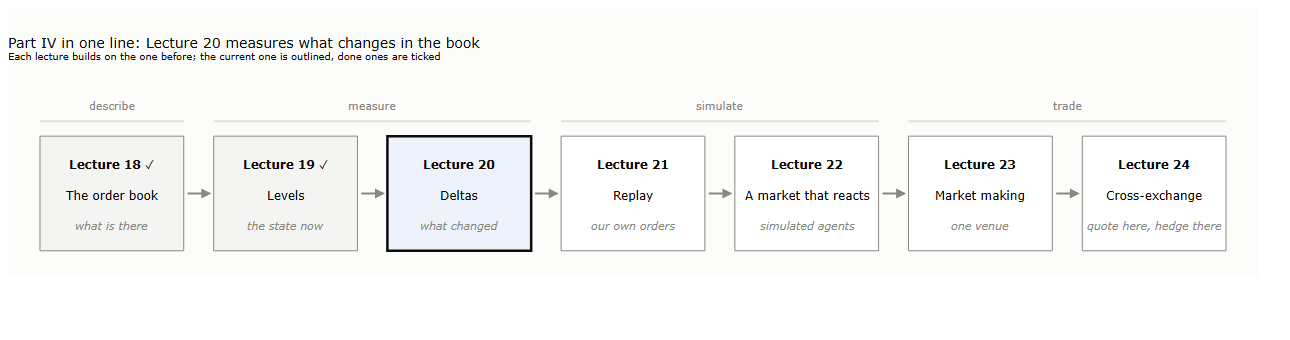

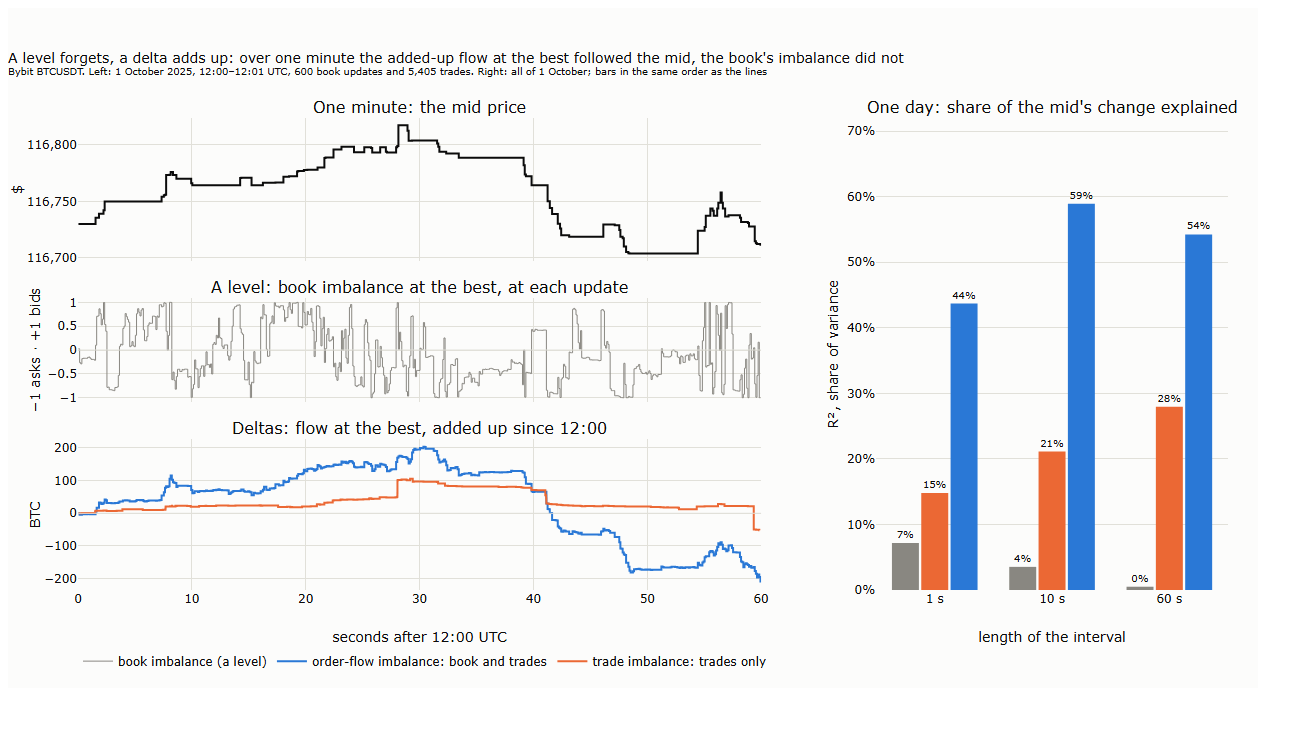

In [2]:
if RUN_CHECK or RUN_ALL:
    if not (L.STATE / f"{CHECK_DAY}.parquet").exists(): run("l19_state.py", CHECK_DAY, lecture=19)
run("l20_s1_charts.py", show=True)
if (L.KEY / "r2.json").exists():
    mine, lec = json.loads((L.KEY / "r2.json").read_text()), shipped("key", "r2.json")
    display(compare([(f"{D} s: share explained by the {n}", lec[D][n], mine[D][n]) for D in lec for n in ("level", "trades", "book")]))
pictures("20_01_part_iv", "20_02_level_vs_delta")

## 2. The five measures on invented flows

The cards of §2 use invented flows, so that what each measure is meant to capture is clear before it meets the data: order-flow imbalance (20_03),
impact over time (20_04), VPIN (20_05), a Hawkes process (20_06) and lead and lag (20_07).

l20_s2_cards.py : 6 s


l20_s2_cards2.py : 11 s


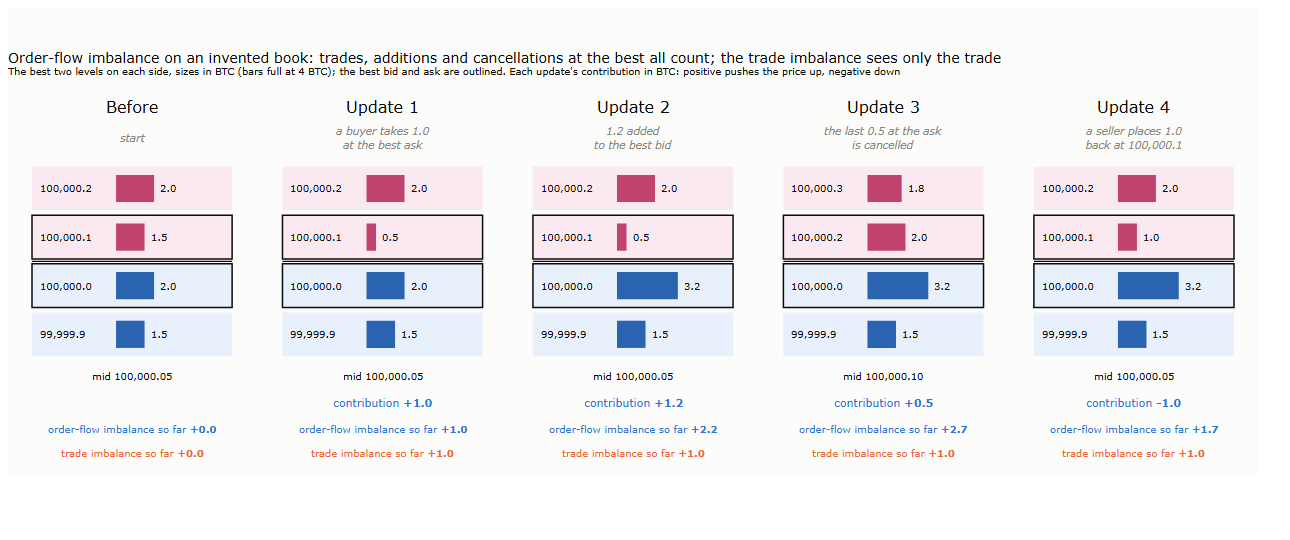

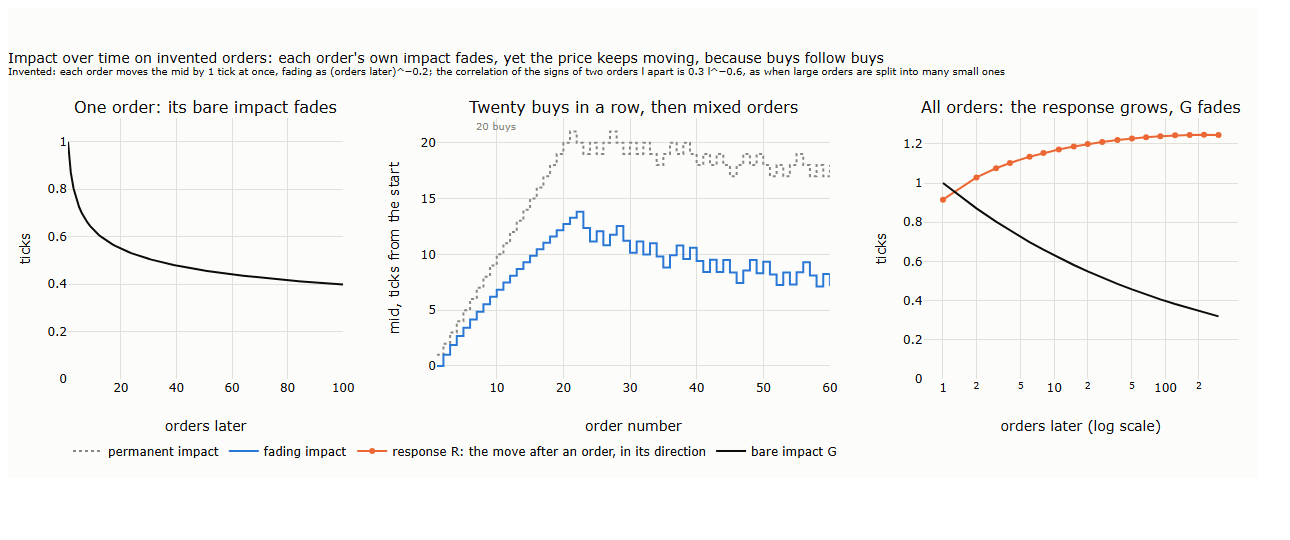

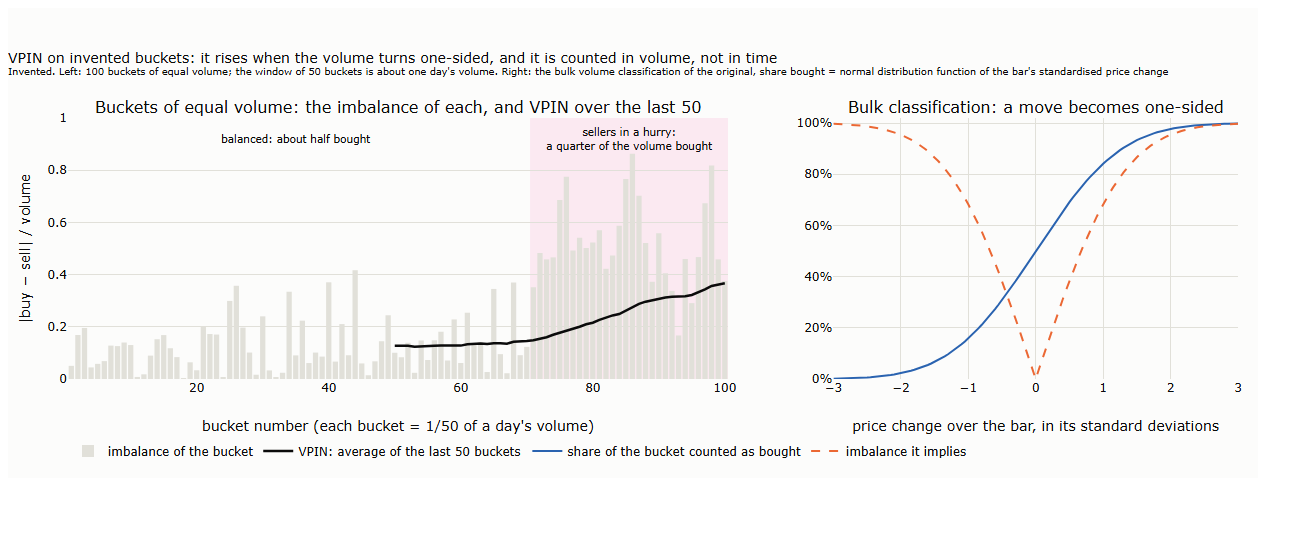

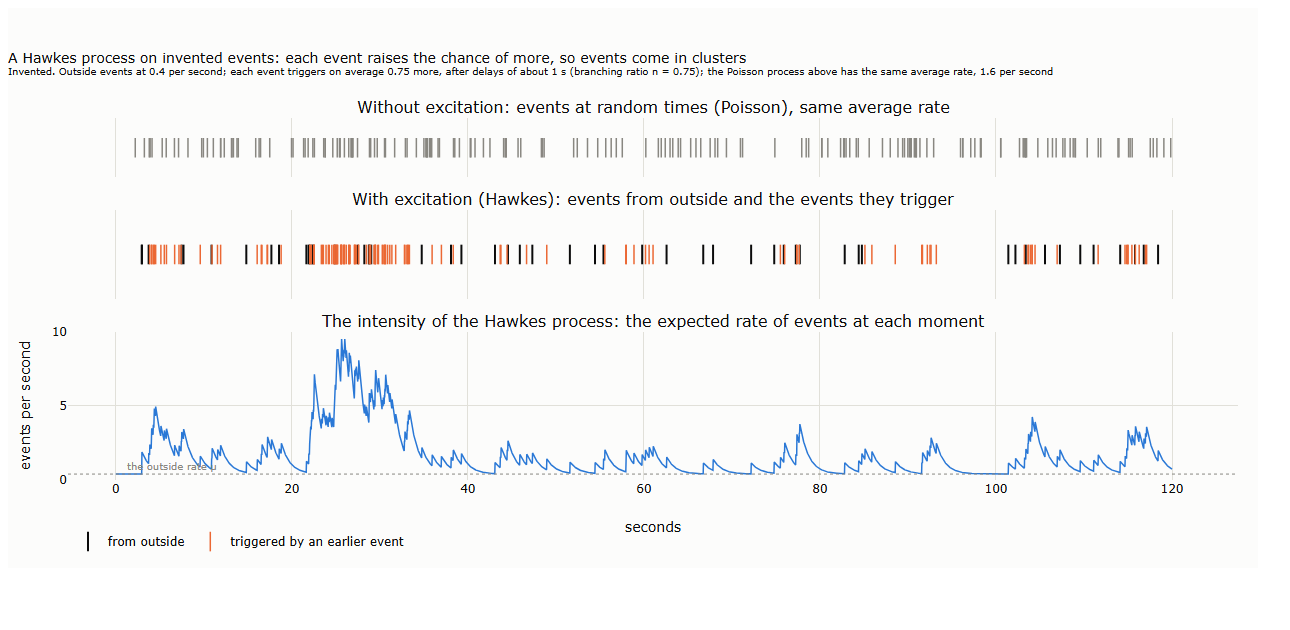

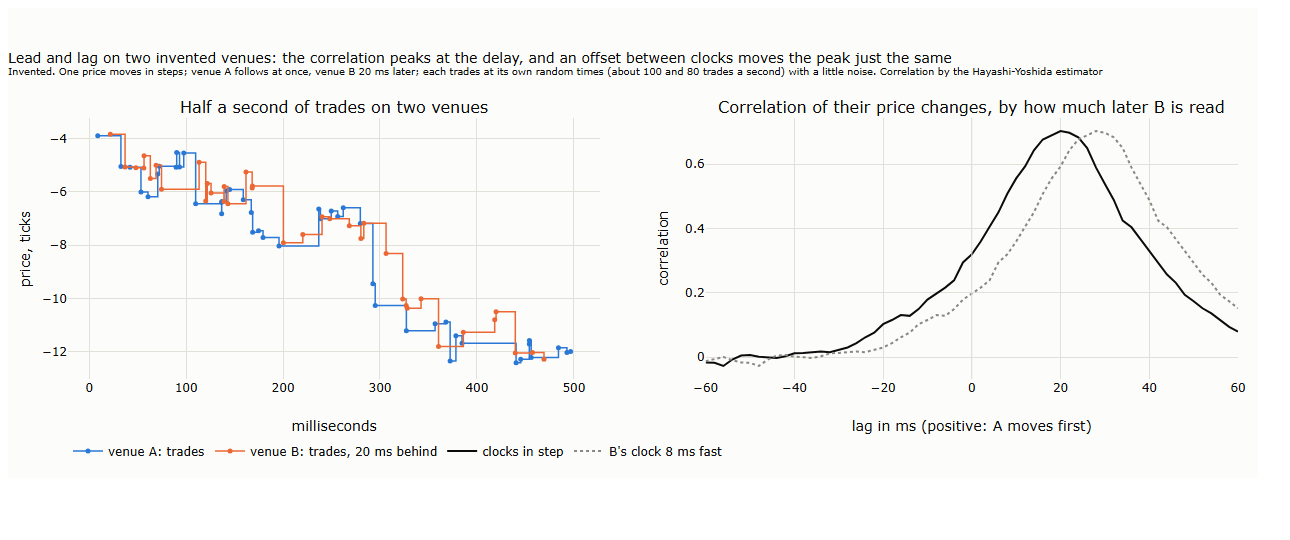

In [3]:
run("l20_s2_cards.py"); run("l20_s2_cards2.py")
pictures("20_03_ofi_card", "20_04_impact_card", "20_05_vpin_card", "20_06_hawkes_card", "20_07_leadlag_card")

## 3. On our 45 days

Two passes per day make the inputs. `l20_orders.py` sums the trades of each venue into taker orders (trades in the same millisecond and on the
same side) and keeps the last price of each millisecond; `l20_book10.py` replays Bybit's book and adds up the order-flow imbalance at each of the
best 10 levels per second. Five scripts then measure: `l20_s3_prop.py` the propagator (H3), `l20_s3_vpin.py` VPIN (H4), `l20_s3_hawkes.py` the
Hawkes process per hour (H5), `l20_s3_leadlag.py` lead and lag (H6), `l20_s3_puzzle.py` and `l20_s3_simpson.py` the Lecture 19 puzzle (H7).

**The check on one day.** With `RUN_CHECK`, every measure except VPIN, whose buckets run across days, is rerun on `CHECK_DAY` and compared with
the lecture's values for that day.

In [4]:
if RUN_CHECK:
    prepare(CHECK_DAY)
    for s in ("l20_s3_prop.py", "l20_s3_hawkes.py", "l20_s3_leadlag.py", "l20_s3_puzzle.py", "l20_s3_simpson.py"): run(s, CHECK_DAY)
    R3 = shipped("s3", "stats.json"); rows = []
    A = L.intervals(CHECK_DAY, 10)                                         # 10-second intervals, as in the test of H1
    for nm, c in (("order-flow imbalance", "ofi"), ("trade imbalance", "ti")):
        cols = ["ofi_1"] if c == "ofi" else ["ti"]; coef = np.array(R3["D10"][c]["coef"]); y = A["dm"].to_numpy()
        pred = np.column_stack([np.ones(len(y)), A.select(cols).to_numpy()]) @ coef
        rows.append((f"R² of the in-sample fit on this day, {nm}", R3["D10"][c]["r2_by_day"][CHECK_DAY], 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()))
    P, P0 = json.loads((L.S3 / "check_prop.json").read_text())[CHECK_DAY], shipped("s3", "prop.json")[CHECK_DAY]
    rows += [("taker orders", P0["n"], P["n"]), ("sign autocorrelation at lag 1", P0["C"][1], P["C"][1]), ("its power-law exponent", P0["gamma"], P["gamma"]),
             ("bare impact G, first order (ticks)", P0["G"][0], P["G"][0]), ("G, 14th order", P0["G"][13], P["G"][13]), ("G, 500th order", P0["G"][499], P["G"][499])]
    H, H0 = pl.read_parquet(L.S3 / "check_hawkes_hours.parquet"), shipped("s3", "hawkes_hours.parquet").filter(pl.col("day") == CHECK_DAY)
    rows += [("Hawkes: hours fitted", H0.height, H.height), ("Hawkes: median branching ratio", H0["n"].median(), H["n"].median())]
    peak = lambda g, c: g.sort("lag")["lag"][int(np.argmax(g.sort("lag")[c].to_numpy()))]
    G, G0 = pl.read_parquet(L.S3 / "check_leadlag.parquet"), shipped("s3", "leadlag.parquet").filter(pl.col("day") == CHECK_DAY)
    rows += [("lead and lag: peak, last trades (ms)", peak(G0, "rho_last"), peak(G, "rho_last")), ("peak, Bybit's mid (ms)", peak(G0, "rho_mid"), peak(G, "rho_mid"))]
    Z, Z0 = json.loads((L.S3 / "check_puzzle.json").read_text())[CHECK_DAY], shipped("s3", "puzzle.json")[CHECK_DAY]
    S, S0 = json.loads((L.S3 / "check_simpson.json").read_text())["days"][CHECK_DAY], shipped("s3", "simpson.json")["days"][CHECK_DAY]
    rows += [("puzzle: rank correlation, last trade", Z0["rho_last"], Z["rho_last"]), ("puzzle: same, Binance's mid", Z0["rho_mid"], Z["rho_mid"]),
             ("Simpson: all samples", S0["all"], S["all"]), ("Simpson: after an up move", S0["within_up"], S["within_up"]), ("after a down move", S0["within_down"], S["within_down"])]
    display(compare(rows))

**Everything, the tests and the figures.** With `RUN_ALL`, both passes and the five measures run on every day, then `l20_s3_stats.py` tests
H1–H7. Otherwise the figures 20_08 to 20_13 are drawn from the shipped results.

l20_s3_charts.py : 14 s


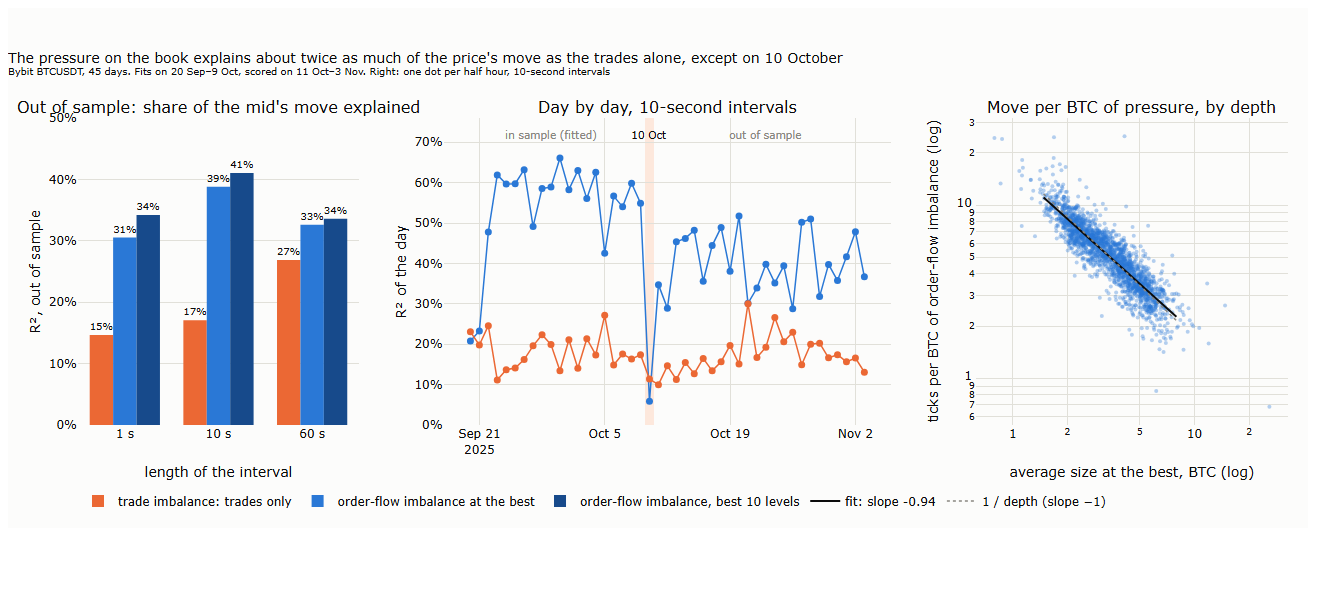

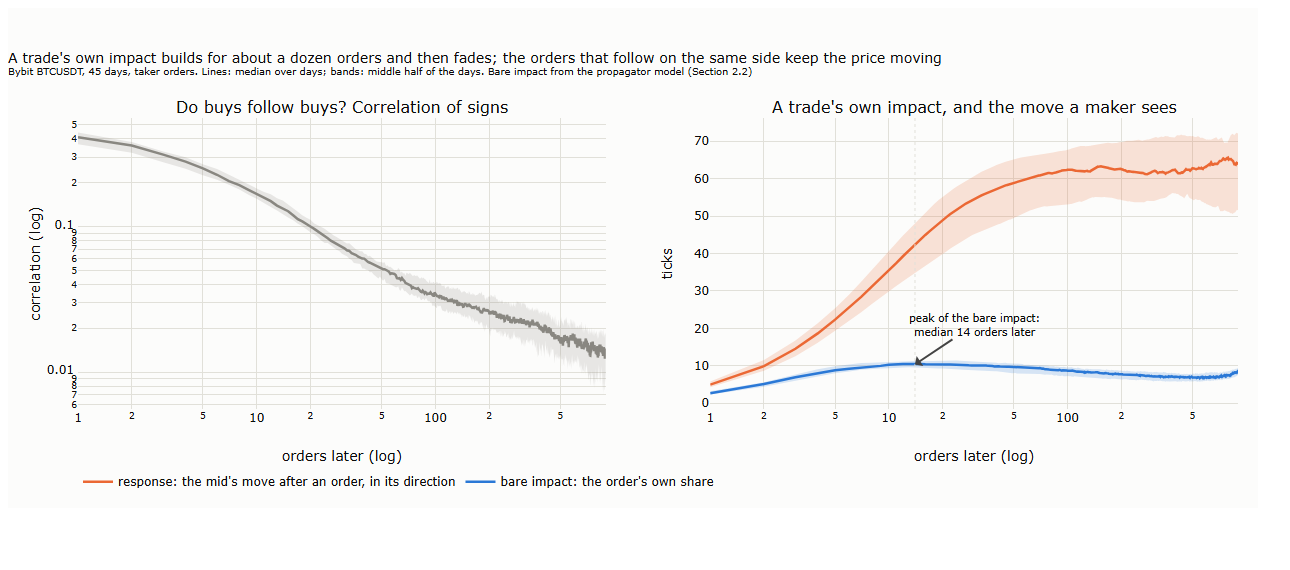

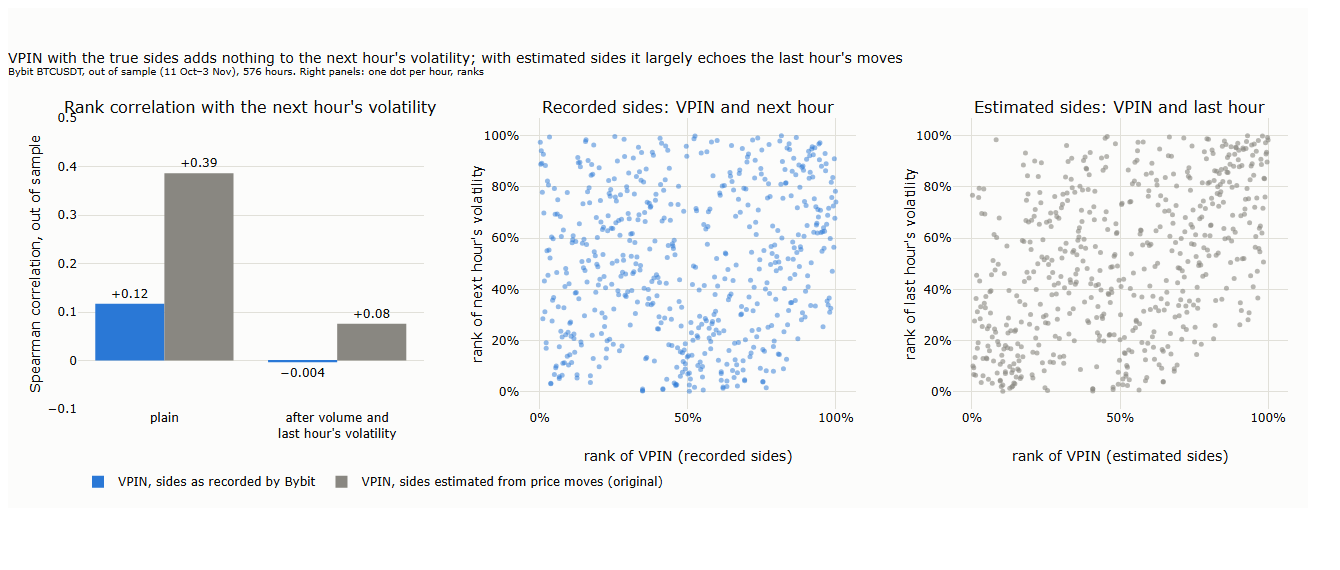

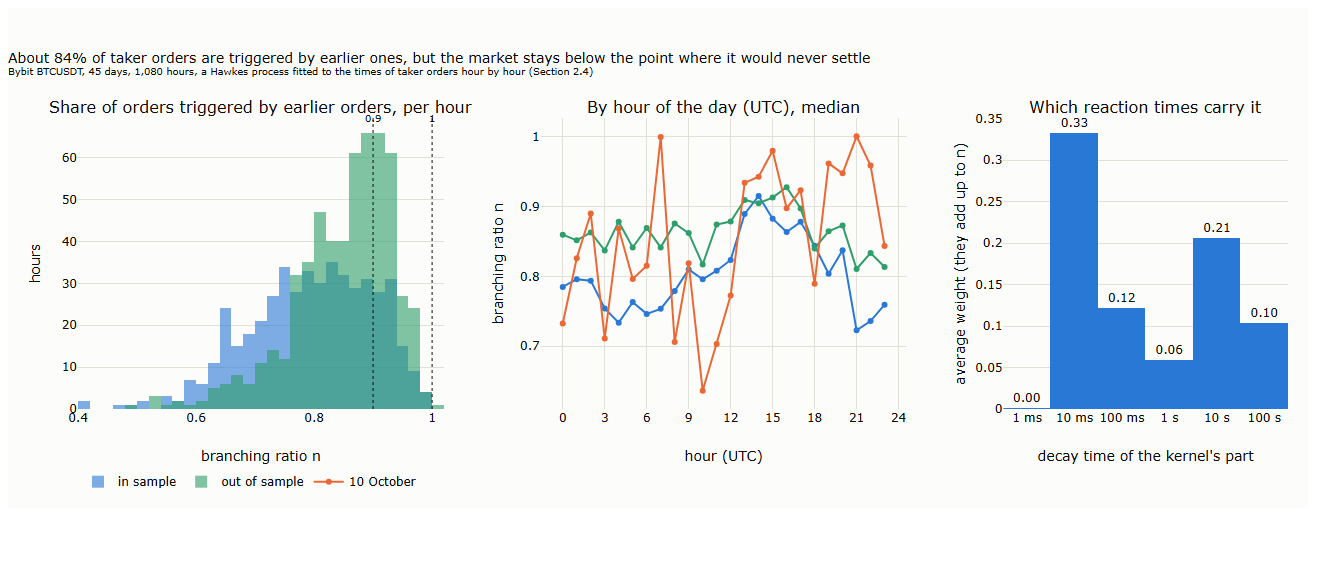

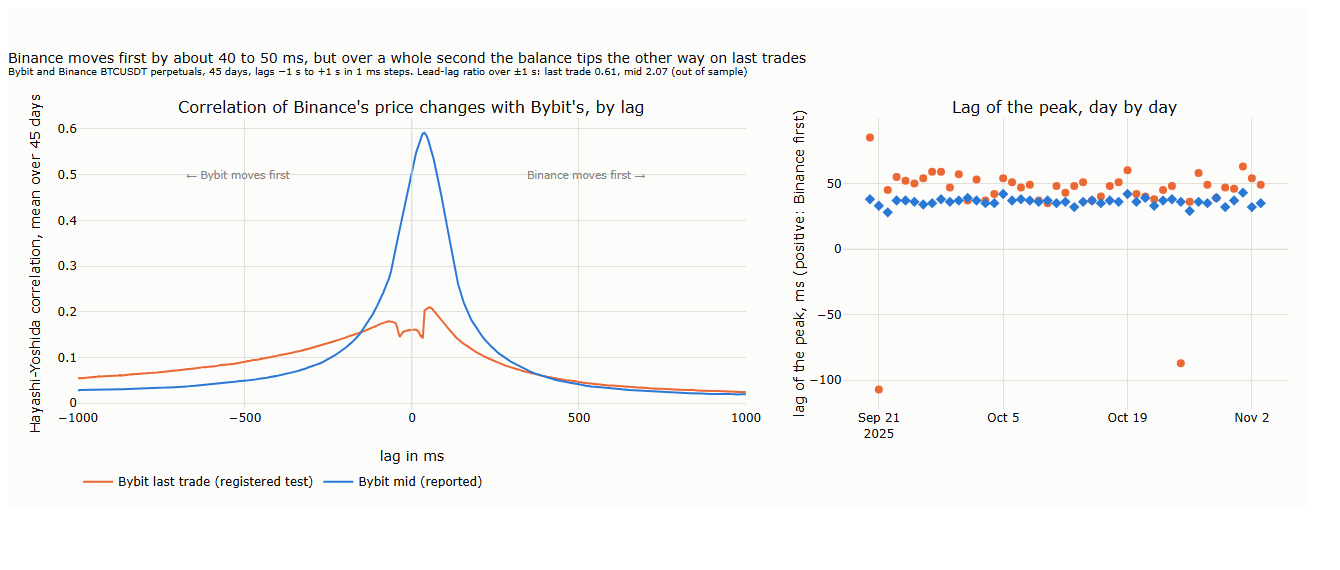

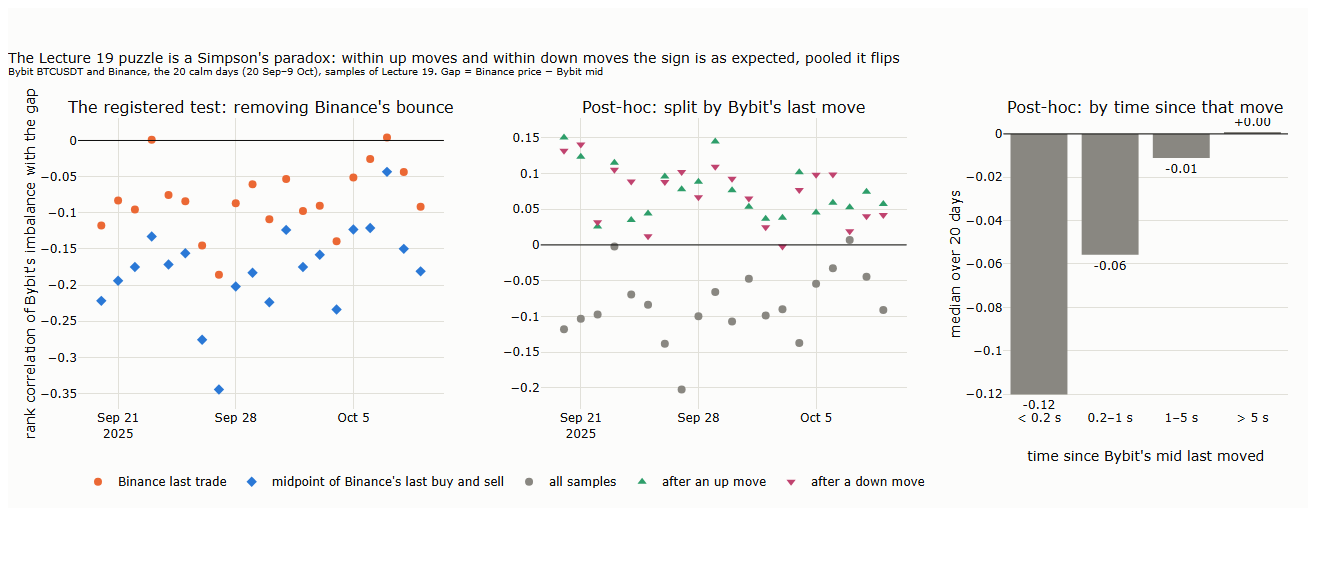

In [5]:
if RUN_ALL:
    for d in L.days(): prepare(d)                                          # skips what is done; Lecture 19's steps first
    for s in ("l20_s3_prop.py", "l20_s3_vpin.py", "l20_s3_hawkes.py", "l20_s3_leadlag.py", "l20_s3_puzzle.py", "l20_s3_simpson.py", "l20_s3_stats.py"): run(s)
run("l20_s3_charts.py")
pictures("20_08_ofi_results", "20_09_impact_results", "20_10_vpin_results", "20_11_hawkes_results", "20_12_leadlag_results", "20_13_puzzle_results")

The verdicts of §3.6, with those of §4: the plain question each test asks, its p-value, and whether it holds after the Benjamini-Hochberg
correction at 5% over the twelve tests (`l20_bh.py`). A p of 0.0005, 1/2001, means that no resample went against the
hypothesis; the lecture writes it as "< 0.001".

In [6]:
QUESTIONS = {"H1": "Does the pressure on the book explain more of a move than the trades?", "H2": "Does the last ten seconds' pressure forecast the next ten?",
             "H3": "Has a trade's own impact faded below where it started?", "H4": "Does VPIN warn of volatility beyond volume and the last hour?",
             "H5": "Does the market stay clearly below the critical point?", "H6": "Does Binance lead Bybit?",
             "H7": "Does Binance's bounce explain the Lecture 19 puzzle?", "H8a": "Was there net selling on Bybit in the hour before the post?",
             "H8b": "Was there net selling on Binance in the hour before the post?", "H9a": "Was trading unusually one-sided in the two hours before?",
             "H9b": "Was the market feeding on itself more than usual?", "H9c": "Did each BTC traded move the price more than usual?"}
if RUN_ALL: run("l20_s4_stats.py"); run("l20_bh.py")
BH = json.loads(L.result_path(L.S4, "bh.json").read_text())
pl.DataFrame([dict(question=QUESTIONS[h], hypothesis=h, p=round(BH[h]["p"], 4), limit=round(BH[h]["threshold"], 4), holds=BH[h]["holds"])
              for h in sorted(BH, key=lambda h: (int(h[1]), h))])

question,hypothesis,p,limit,holds
str,str,f64,f64,bool
"""Does the pressure on the book explain more of a move than the trades?""","""H1""",0.0005,0.0042,true
"""Does the last ten seconds' pressure forecast the next ten?""","""H2""",0.0005,0.0083,true
"""Has a trade's own impact faded below where it started?""","""H3""",1.0,0.0417,false
"""Does VPIN warn of volatility beyond volume and the last hour?""","""H4""",0.526,0.025,false
"""Does the market stay clearly below the critical point?""","""H5""",0.0005,0.0125,true
"""Does Binance lead Bybit?""","""H6""",1.0,0.0458,false
"""Does Binance's bounce explain the Lecture 19 puzzle?""","""H7""",1.0,0.05,false
"""Was there net selling on Bybit in the hour before the post?""","""H8a""",0.996,0.0375,false
"""Was there net selling on Binance in the hour before the post?""","""H8b""",0.8455,0.0292,false


## 4. 10 October

`l20_s4_stats.py` compares the hour and the two hours before the tariff post (20:50:01.7 UTC) with every window of the same length and clock
phase on the other 44 days (H8, H9). `l20_s4_warn.py` builds, per minute on all 45 days, the thirteen measures of the early-warning table, among
them Lecture 19's depth, refilling chains and publish delay and Lecture 18's pulls, and flags five minutes in a row beyond the 99th percentile of
the calm days. Both need all days, so they run only with `RUN_ALL`; the figures are otherwise drawn from the shipped results.

l20_s4_charts.py : 9 s


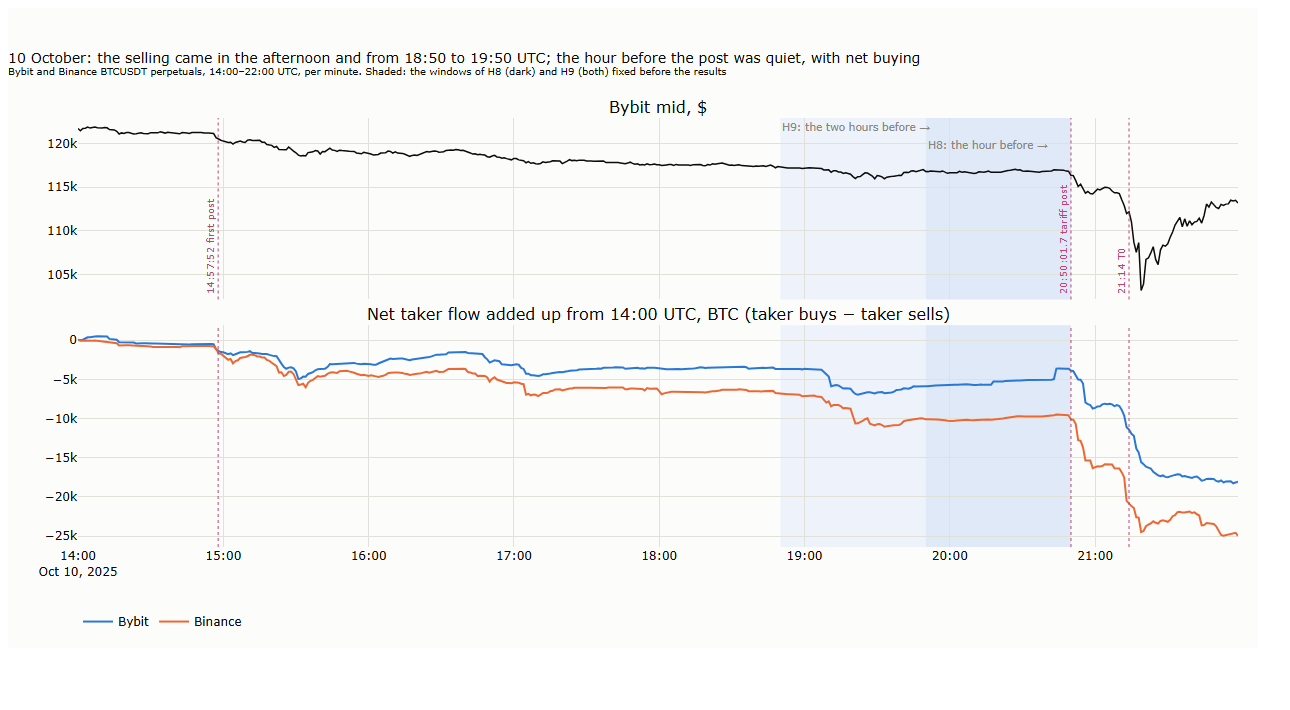

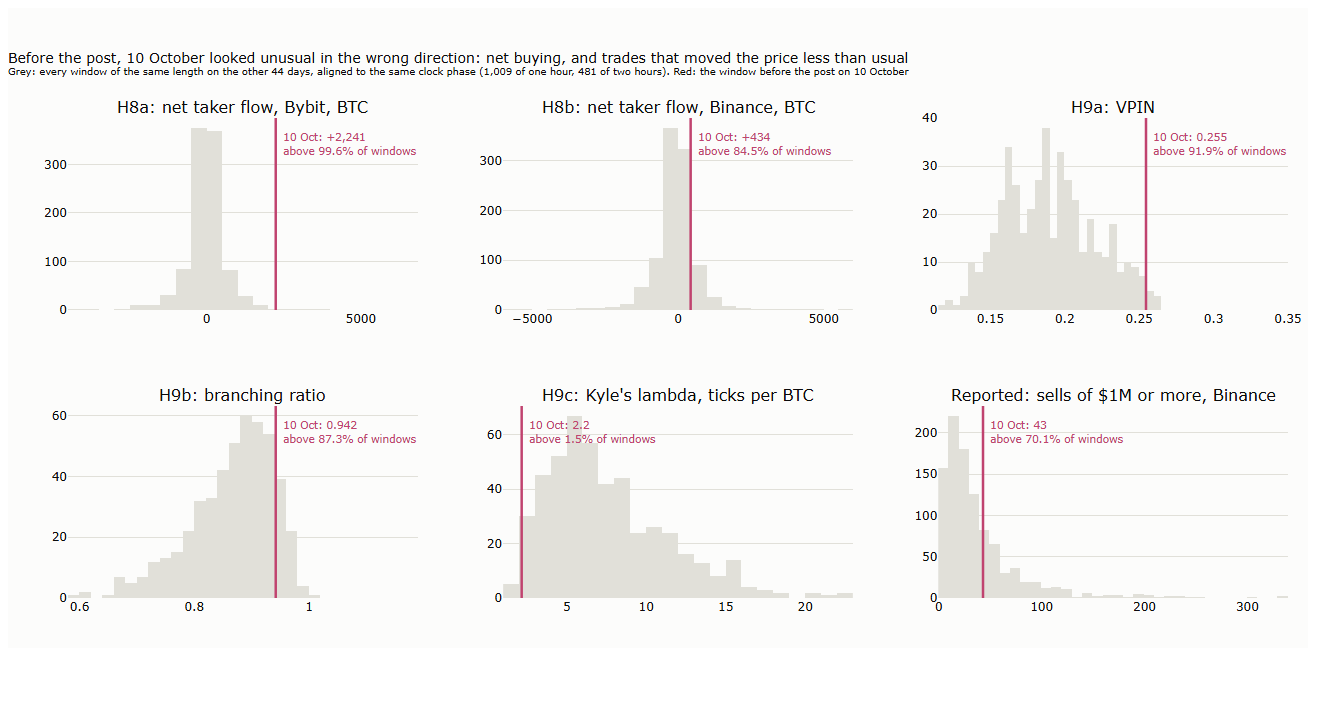

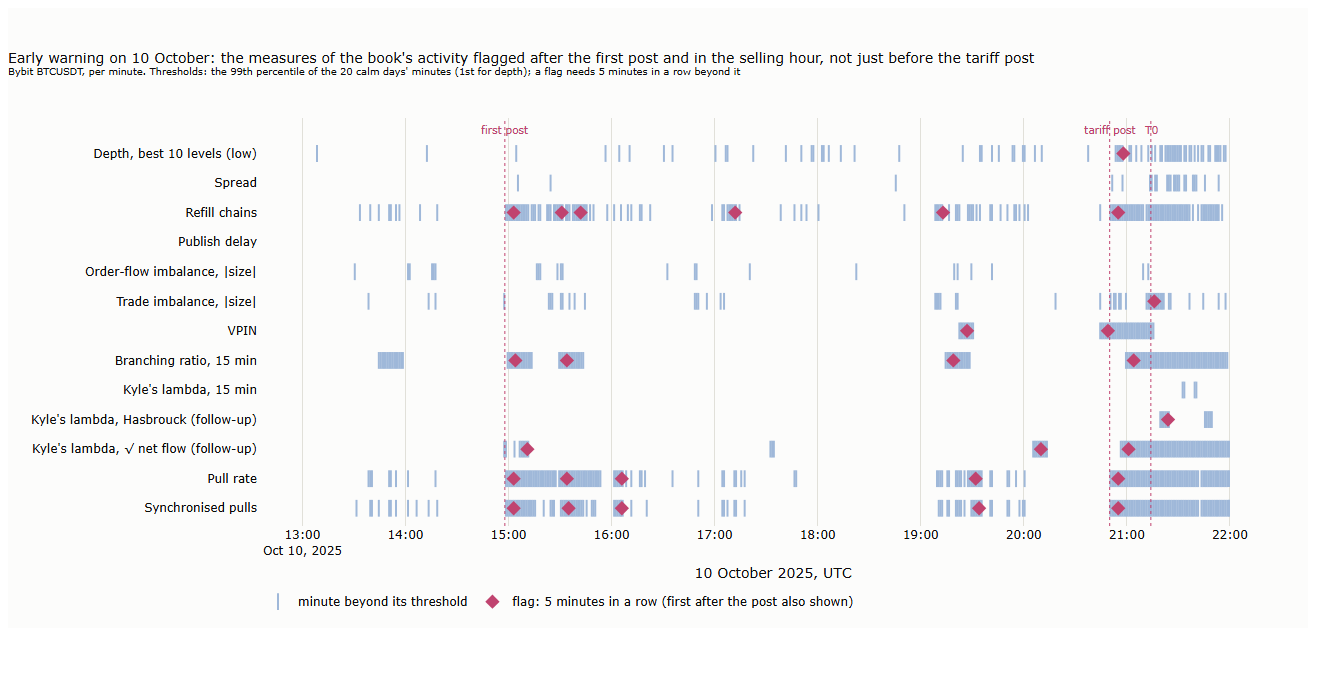

In [7]:
if RUN_ALL:
    for d in L.days(): prepare(d, queues=True)                             # Lecture 19's queue passes and Lecture 18's pulls: about 3 minutes a day
    run("l20_s4_warn.py")
run("l20_s4_charts.py")
pictures("20_14_evening", "20_15_before_post", "20_16_early_warning")

The tests of §4: the value in the window before the post, the median of the reference windows, and the p-value.

In [8]:
R4 = json.loads(L.result_path(L.S4, "stats.json").read_text())
rows = [("H8a", "net taker flow, Bybit, BTC", "1h", "ti_bybit"), ("H8b", "net taker flow, Binance, BTC", "1h", "ti_binance"), ("H9a", "VPIN", "2h", "vpin"),
        ("H9b", "branching ratio", "2h", "hawkes_n"), ("H9c", "Kyle's lambda, ticks per BTC", "2h", "kyle_lambda")]
pl.DataFrame([dict(hypothesis=h, measure=m, before_post=round(R4[w]["pre"][c], 3), reference_median=round(R4[w]["ref_q"][c], 3),
                   reference_windows=R4[w]["n_ref"], p=round(R4[f"{h}_p"], 4)) for h, m, w, c in rows])

hypothesis,measure,before_post,reference_median,reference_windows,p
str,str,f64,f64,i64,f64
"""H8a""","""net taker flow, Bybit, BTC""",2240.767,-7.702,1009,0.996
"""H8b""","""net taker flow, Binance, BTC""",433.671,-40.54,1009,0.8455
"""H9a""","""VPIN""",0.255,0.191,481,0.0178
"""H9b""","""branching ratio""",0.942,0.879,481,0.1286
"""H9c""","""Kyle's lambda, ticks per BTC""",2.166,6.686,481,0.9855


The early-warning table of §4.3: the flags in the six hours before the post, the first flag after it, and the false alarms per day.

In [9]:
W = json.loads(L.result_path(L.S4, "warn.json").read_text())
hm = lambda t: str(np.datetime64(int(t), "ms"))[11:16]
NAMES = {"depth": "Depth, best 10 levels", "spread": "Spread", "chains": "Refill chains (L19)", "delay": "Publish delay (L19)", "ofi": "Order-flow imbalance",
         "ti": "Trade imbalance", "vpin": "VPIN", "hawkes": "Branching ratio, 15 min", "kyle": "Kyle's lambda, 15 min",
         "kyle_hasb": "Kyle's lambda, Hasbrouck form (follow-up)", "kyle_sqrt": "Kyle's lambda, square root of net flow (follow-up)",
         "pulls": "Pull rate", "sync": "Synchronised pulls"}
pl.DataFrame([dict(measure=NAMES[c], flags_before_post=", ".join(hm(t) for t in v["pre_times"]) or "none",
                   first_flag_after=(f"+{v['first_post_min']:.0f} min" if v["first_post_min"] is not None
                                     else "(already flagged)" if v["pre_times"] and L.POST - max(v["pre_times"]) < 5 * 60_000 else "none"),
                   false_alarms_calm=round(v["fa_ins"], 2), false_alarms_after=round(v["fa_oos"], 2)) for c, v in ((c, W["ind"][c]) for c in NAMES)])

measure,flags_before_post,first_flag_after,false_alarms_calm,false_alarms_after
str,str,str,f64,f64
"""Depth, best 10 levels""","""none""","""+8 min""",0.0,7.12
"""Spread""","""none""","""none""",0.0,0.0
"""Refill chains (L19)""","""15:03, 15:31, 15:42, 17:12, 19:13""","""+5 min""",0.15,1.96
"""Publish delay (L19)""","""none""","""none""",0.0,0.08
"""Order-flow imbalance""","""none""","""none""",0.0,0.0
"""Trade imbalance""","""none""","""+26 min""",0.05,0.0
"""VPIN""","""19:27, 20:49""","""(already flagged)""",0.3,0.17
"""Branching ratio, 15 min""","""15:04, 15:34, 19:19""","""+14 min""",0.8,2.46
"""Kyle's lambda, 15 min""","""none""","""none""",1.1,4.0


## 5. The follow-ups

The lecture labels as follow-ups the checks made after the results. Each script prints its table and keeps a copy in `L20_OUT/followups`.

**The audits of H3 and H6** use `CHECK_DAY`, 1 October, so they run with `RUN_CHECK`. `l20_prop_check.py` simulates a mid with a known
impact on the day's real order signs: the solver should recover it to two decimals when the mid is fresh (A), and show a rise of a few orders when the
mid is read only at book updates (B); in book-update time the real impact should build from about 9.9 ticks to about 14 before it fades (C).
`l20_prop_check2.py` follows the mid over the book updates around each taker order: it should jump at the very next update, a median 50 ms
later, by about 22, 43 and 86 ticks for the three sizes. `l20_ll_check.py` simulates a 40 ms lead of Binance on the real trade times of
12:00–14:00; the lecture's table reads 1.11, 1.18, 1.25 and 1.31 for the simulated ratio within ±50, ±100, ±200 ms and ±1 s.

In [10]:
if RUN_CHECK:
    prepare(CHECK_DAY)
    for s in ("l20_prop_check.py", "l20_prop_check2.py", "l20_ll_check.py"): run(s, show=True)
else:
    print("RUN_CHECK is off: the audits of H3 and H6 are not rerun.")

RUN_CHECK is off: the audits of H3 and H6 are not rerun.


**Kyle's lambda and the price before the post** read all 45 days, so they run with `RUN_FOLLOWUPS` after `RUN_ALL`. The lecture's values:
`l20_kyle_check.py`, rank correlation of the 15-minute per-BTC lambda with volume −0.60 on the calm days; `l20_kyle_check3.py`, its exponent on
volume −0.46 and the square-root variant's percentiles; `l20_kyle_hasb.py`, the table of §4.3 by block length (Hasbrouck's form, H9c follow-up
p = 0.83); `l20_kyle_bcst.py`, the buy and sell lambdas of Brennan et al., sell over buy 0.98 on the calm days and 1.01 after 10 October, the two
hours before the post p = 0.64; `l20_predrift.py`, the table of §4.2, the return before the post against about 1,050 reference windows.

In [11]:
FOLLOWUPS = ("l20_kyle_check.py", "l20_kyle_check3.py", "l20_kyle_hasb.py", "l20_kyle_bcst.py", "l20_predrift.py")
if RUN_FOLLOWUPS:
    for s in FOLLOWUPS: run(s, show=True)                                  # one at a time: each reads all 45 days
else:
    print("RUN_FOLLOWUPS is off. Earlier printouts, if any:")
    for s in FOLLOWUPS:
        f = L.FOLLOW / f"{s[4:-3]}.txt"
        print(f"\n--- {s}\n" + (f.read_text(encoding="utf-8") if f.exists() else "(not run yet)"))

RUN_FOLLOWUPS is off. Earlier printouts, if any:

--- l20_kyle_check.py
(not run yet)

--- l20_kyle_check3.py
(not run yet)

--- l20_kyle_hasb.py
(not run yet)

--- l20_kyle_bcst.py
(not run yet)

--- l20_predrift.py
(not run yet)


## 6. A test of your own: the branching ratio through the day

Section 3.4 found the branching ratio higher in the hours when US markets were open. Here it is by hour of the day from the shipped results:
the median over days, with the share of hours below 0.9 (the threshold of H5), in and out of sample. Change the grouping (weekday against
weekend, or before and after 10 October), or take another column of `hawkes_hours.parquet`: the weights `a_*` show which time scales of the kernel
carry the triggering.

In [12]:
Hk = pl.read_parquet(L.result_path(L.S3, "hawkes_hours.parquet")).with_columns(
    pl.when(pl.col("day") < L.CASC).then(pl.lit("in sample")).when(pl.col("day") > L.CASC).then(pl.lit("out of sample")).otherwise(pl.lit("10 October")).alias("sample"))
(Hk.filter(pl.col("sample") != "10 October").group_by("hour", "sample").agg(pl.col("n").median().alias("median n"), (pl.col("n") < 0.9).mean().alias("share below 0.9"),
                                                                           pl.col("events").median().alias("median orders"))
   .sort("hour", "sample").pivot(on="sample", index="hour", values=["median n", "share below 0.9"]))

hour,median n_in sample,median n_out of sample,share below 0.9_in sample,share below 0.9_out of sample
i64,f64,f64,f64,f64
0,0.784858,0.859662,0.85,0.75
1,0.795871,0.851615,0.95,0.708333
2,0.793837,0.862825,0.9,0.708333
3,0.753975,0.837201,0.95,0.833333
4,0.733702,0.878292,0.85,0.541667
5,0.763127,0.841349,0.9,0.875
6,0.746288,0.869278,0.85,0.708333
7,0.753464,0.841497,0.85,0.833333
8,0.77897,0.875678,0.85,0.875
